#### Import libraries

In [ ]:
import geopandas as gpd
from sqlalchemy import text, create_engine
import numpy as np
import pandas as pd
from matplotlib.colors import to_hex, to_rgb
from matplotlib.patches import Patch
import seaborn as sns
import matplotlib.ticker as mticker
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import PercentFormatter

#### Connection DB

In [ ]:
# Connection with the DB
engine = create_engine("postgresql://mobiledata:@cirrus.ita.chalmers.se/se_mobile_data",
                       connect_args={"client_encoding": "utf8"})
conn = engine.connect()

#### Import data

In [137]:
YEARS = (#2023,
         2024,)
         #2025)

PARK_SCHEMA = "extracts"
PARK_TABLE_PREFIX = "swe_proto_movement_national_parks"
PARK_COL = "namn"
PARKS = (
    "Abisko",
    "Skuleskogen",
    "Kosterhavets nationalpark",
)

STATS_SCHEMA = "processed"
STATS_TABLE = "stats_devices"
STATS_YEAR_COL = "year"
STATS_MONTH_COL = "month"
STATS_DEVICE_COL = "devices"

TIMESTAMP_COL = "arrive_time"
DEVICE_COL = "device_aid"
GEOM_COL = "geom"
EPSG = 4326

default_palette = {
    "Abisko": {
        2023: "#A9D6E5",
        2024: "#61A5C2",
        2025: "#277DA1",
    },

    # Woodland greens
    "Skuleskogen": {
        2023: "#B7D69A",
        2024: "#7AAA55",
        2025: "#4F772D",
    },

    # Coastal blues
    "Kosterhavets nationalpark": {
        2023: "#A7C4A0",
        2024: "#5B8E57",
        2025: "#31572C",
    },
}

park_labels = {
        "Abisko": "Abisko",
        "Skuleskogen": "Skuleskogen",
        "Kosterhavets nationalpark": "Kosterhavet",
}

In [138]:
# Import aggregated national park data
def read_spatial_table(
        engine,
        schema,
        table,
        *,
        geom_col=GEOM_COL,
        epsg=EPSG,
):
    query = text(
        f'SELECT * FROM "{schema}"."{table}"'
    )

    gdf = gpd.read_postgis(
        query,
        con=engine,
        geom_col=geom_col,
    )

    if gdf.crs is None:
        gdf = gdf.set_crs(
            epsg=epsg,
            allow_override=True,
        )
    elif gdf.crs.to_epsg() != epsg:
        gdf = gdf.to_crs(
            epsg=epsg,
        )

    return gdf


def import_park_data(
        engine,
        *,
        years=YEARS,
        schema=PARK_SCHEMA,
        table_prefix=PARK_TABLE_PREFIX,
        geom_col=GEOM_COL,
):
    output = {}

    for year in years:
        table = f"{table_prefix}_{year}"

        output[year] = read_spatial_table(
            engine=engine,
            schema=schema,
            table=table,
            geom_col=geom_col,
        )

        print(
            f"{year}: "
            f"{len(output[year]):,} rows"
        )

    return output


def read_table(
        engine,
        schema,
        table,
):
    query = text(
        f'SELECT * FROM "{schema}"."{table}"'
    )

    return pd.read_sql(
        query,
        con=engine,
    )


# Import national-park movement tables by year

park_data = import_park_data(
    engine=engine,
)

#parks_2023 = park_data[2023]
parks_2024 = park_data[2024]
#parks_2025 = park_data[2025]

# Import device statistics

stats_device = read_table(
    engine=engine,
    schema=STATS_SCHEMA,
    table=STATS_TABLE,
)

print(
    f"{STATS_SCHEMA}.{STATS_TABLE}: "
    f"{len(stats_device):,} rows"
)

2024: 15,207 rows
processed.stats_devices: 24 rows


In [139]:
# Create monthly park table
# Create monthly park table

def parse_timestamp(values):
    numeric_values = pd.to_numeric(
        values,
        errors="coerce",
    )

    # Treat the column as Unix time when most non-null
    # values can be converted to numbers.
    numeric_ratio = (
        numeric_values.notna().mean()
    )

    if numeric_ratio >= 0.80:
        valid_values = numeric_values.dropna()

        unit = (
            "ms"
            if valid_values.median() > 10_000_000_000
            else "s"
        )

        return pd.to_datetime(
            numeric_values,
            unit=unit,
            errors="coerce",
            utc=True,
        )

    return pd.to_datetime(
        values,
        errors="coerce",
        utc=True,
    )


def create_parks_table(
        park_data,
        *,
        years=YEARS,
        parks=PARKS,
        park_col=PARK_COL,
        device_col=DEVICE_COL,
        timestamp_col=TIMESTAMP_COL,
):
    summaries = []

    for year in years:
        if year not in park_data:
            print(f"Missing data for {year}")
            continue

        data = park_data[year].copy()

        required_columns = {
            park_col,
            device_col,
            timestamp_col,
        }

        missing_columns = required_columns.difference(
            data.columns
        )

        if missing_columns:
            raise KeyError(
                f"Missing columns in {year}: "
                f"{sorted(missing_columns)}"
            )

        datetime_values = parse_timestamp(
            data[timestamp_col]
        )

        data["month"] = (
            datetime_values
            .dt.tz_localize(None)
            .dt.to_period("M")
            .dt.to_timestamp()
        )

        data = data.loc[
            data[park_col].isin(parks)
            & data["month"].notna()
            ].copy()

        print(
            f"{year}: {len(data):,} matching records"
        )

        summary = (
            data
            .groupby(
                [
                    "month",
                    park_col,
                ],
                as_index=False,
            )
            .agg(
                total_records=(
                    device_col,
                    "size",
                ),
                unique_devices=(
                    device_col,
                    "nunique",
                ),
            )
            .rename(
                columns={
                    park_col: "park",
                }
            )
        )

        summaries.append(summary)

    if not summaries:
        return pd.DataFrame(
            columns=[
                "month",
                "park",
                "total_records",
                "unique_devices",
            ]
        )

    parks_table = (
        pd.concat(
            summaries,
            ignore_index=True,
        )
        .sort_values(
            [
                "month",
                "park",
            ]
        )
        .reset_index(drop=True)
    )

    return parks_table


parks_table = create_parks_table(
    park_data=park_data,
)

parks_table.head()

2024: 15,207 matching records


,month,park,total_records,unique_devices
0,2024-01-01,Abisko,850,164
1,2024-01-01,Kosterhavets nationalpark,134,60
2,2024-01-01,Skuleskogen,719,169
3,2024-02-01,Abisko,331,96
4,2024-02-01,Kosterhavets nationalpark,32,23


In [140]:
# Create normalized device table
def create_normalized_devices(
        parks_table,
        stats_device,
        *,
        stats_year_col=STATS_YEAR_COL,
        stats_month_col=STATS_MONTH_COL,
        stats_device_col=STATS_DEVICE_COL,
):
    stats = stats_device.copy()

    required_columns = {
        stats_year_col,
        stats_month_col,
        stats_device_col,
    }

    missing_columns = required_columns.difference(
        stats.columns
    )

    if missing_columns:
        raise KeyError(
            "Missing columns in stats_device: "
            f"{sorted(missing_columns)}"
        )

    stats[stats_year_col] = pd.to_numeric(
        stats[stats_year_col],
        errors="coerce",
    )

    stats[stats_month_col] = pd.to_numeric(
        stats[stats_month_col],
        errors="coerce",
    )

    stats[stats_device_col] = pd.to_numeric(
        stats[stats_device_col],
        errors="coerce",
    )

    stats["month"] = pd.to_datetime(
        {
            "year": stats[stats_year_col],
            "month": stats[stats_month_col],
            "day": 1,
        },
        errors="coerce",
    )

    monthly_totals = (
        stats
        .dropna(
            subset=[
                "month",
                stats_device_col,
            ]
        )
        .groupby(
            "month",
            as_index=False,
        )
        .agg(
            total_devices=(
                stats_device_col,
                "sum",
            )
        )
    )

    normalized_devices = (
        parks_table
        .merge(
            monthly_totals,
            on="month",
            how="left",
            validate="many_to_one",
        )
    )

    normalized_devices["normalized_devices"] = (
        normalized_devices["unique_devices"]
        .div(
            normalized_devices["total_devices"]
            .replace(0, pd.NA)
        )
    )

    normalized_devices[
        "normalized_devices_percent"
    ] = (
            normalized_devices["normalized_devices"]
            * 100
    )

    return normalized_devices[
        [
            "month",
            "park",
            "total_records",
            "unique_devices",
            "total_devices",
            "normalized_devices",
            "normalized_devices_percent",
        ]
    ]


normalized_devices = create_normalized_devices(
    parks_table=parks_table,
    stats_device=stats_device,
)

normalized_devices.head()

,month,park,total_records,unique_devices,total_devices,normalized_devices,normalized_devices_percent
0,2024-01-01,Abisko,850,164,1806378,0.000091,0.009079
1,2024-01-01,Kosterhavets nationalpark,134,60,1806378,0.000033,0.003322
2,2024-01-01,Skuleskogen,719,169,1806378,0.000094,0.009356
3,2024-02-01,Abisko,331,96,1724641,0.000056,0.005566
4,2024-02-01,Kosterhavets nationalpark,32,23,1724641,0.000013,0.001334


In [141]:
# Plot
def plot_combined_devices_by_month(
        data,
        plot_title,
        *,
        years=YEARS,
        parks=PARKS,
        month_col="month",
        park_col="park",
        devices_col="unique_devices",
        normalized_col="normalized_devices_percent",
        save_path=None,
):

    plt.close("all")
    plt.style.use("default")

    sns.set_theme(
        context="notebook",
        style="white",
        font_scale=1.0,
        rc={
            "figure.facecolor": "white",
            "axes.facecolor": "#FCFCFA",
            "axes.edgecolor": "#CBD1C8",
            "axes.labelcolor": "#354239",
            "text.color": "#26382D",
            "xtick.color": "#4D5A51",
            "ytick.color": "#4D5A51",
        },
    )

    month_labels = (
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "May",
        "Jun",
        "Jul",
        "Aug",
        "Sep",
        "Oct",
        "Nov",
        "Dec",
    )

    required_columns = {
        month_col,
        park_col,
        devices_col,
        normalized_col,
    }

    missing_columns = required_columns.difference(
        data.columns
    )

    if missing_columns:
        raise KeyError(
            "Missing visualization columns: "
            f"{sorted(missing_columns)}"
        )

    years = tuple(years)
    parks = tuple(parks)

    if not years:
        raise ValueError(
            "'years' must contain at least one year."
        )

    if not parks:
        raise ValueError(
            "'parks' must contain at least one park."
        )

    plot_data = data.copy()

    plot_data[month_col] = pd.to_datetime(
        plot_data[month_col],
        errors="coerce",
    )

    plot_data[devices_col] = pd.to_numeric(
        plot_data[devices_col],
        errors="coerce",
    )

    plot_data[normalized_col] = pd.to_numeric(
        plot_data[normalized_col],
        errors="coerce",
    )

    plot_data["year"] = (
        plot_data[month_col].dt.year
    )

    plot_data["calendar_month"] = (
        plot_data[month_col].dt.month
    )

    plot_data = (
        plot_data.loc[
            plot_data[park_col].isin(parks)
            & plot_data["year"].isin(years)
            & plot_data["calendar_month"].notna()
            ]
        .sort_values(
            [
                park_col,
                "year",
                "calendar_month",
            ]
        )
        .copy()
    )

    if plot_data.empty:
        raise ValueError(
            "No observations match the selected parks and years."
        )

    duplicate_rows = plot_data.duplicated(
        subset=[
            park_col,
            "year",
            "calendar_month",
        ],
        keep=False,
    )

    if duplicate_rows.any():
        duplicate_keys = (
            plot_data.loc[
                duplicate_rows,
                [
                    park_col,
                    "year",
                    "calendar_month",
                ],
            ]
            .drop_duplicates()
            .head(10)
            .to_dict("records")
        )

        raise ValueError(
            "Multiple rows were found for the same park, year, "
            "and month. Aggregate the data before plotting. "
            f"Examples: {duplicate_keys}"
        )

    figure_height = max(
        10.5,
        3.25 * len(parks),
    )

    fig, axes = plt.subplots(
        nrows=len(parks),
        ncols=1,
        figsize=(12, figure_height),
        sharex=True,
        squeeze=False,
        constrained_layout=False,
    )

    axes = axes[:, 0]

    x_months = np.arange(
        1,
        13,
        dtype=float,
    )

    group_width = 0.72
    bar_width = group_width / len(years)

    year_offsets = {
        year: (
                      index - (len(years) - 1) / 2
              ) * bar_width
        for index, year in enumerate(years)
    }

    for row, park in enumerate(parks):
        ax_devices = axes[row]
        ax_share = ax_devices.twinx()

        park_palette = park_palettes.get(
            park,
            default_palette,
        )

        park_color = park_palette.get(
            max(years),
            "#405743",
        )

        for year in years:
            color = park_palette.get(
                year,
                park_color,
            )

            yearly_data = (
                plot_data.loc[
                    (plot_data[park_col] == park)
                    & (plot_data["year"] == year),
                    [
                        "calendar_month",
                        devices_col,
                        normalized_col,
                    ],
                ]
                .set_index(
                    "calendar_month"
                )
                .reindex(
                    range(1, 13)
                )
            )

            x_positions = (
                    x_months
                    + year_offsets[year]
            )

            ax_devices.bar(
                x_positions,
                yearly_data[devices_col],
                width=bar_width * 0.88,
                color=color,
                alpha=0.82,
                edgecolor="white",
                linewidth=0.7,
                zorder=2,
            )

            ax_share.plot(
                x_months,
                yearly_data[normalized_col],
                color=color,
                linewidth=2.2,
                marker="o",
                markersize=4.8,
                markerfacecolor=color,
                markeredgecolor="white",
                markeredgewidth=0.8,
                solid_capstyle="round",
                zorder=4,
            )

        ax_devices.set_title(
            park_labels.get(
                park,
                park,
            ),
            loc="center",
            fontsize=14,
            fontweight="bold",
            color=park_color,
            pad=14,
        )

        ax_devices.set_ylabel(
            "Unique devices",
            fontsize=10.5,
            fontweight="medium",
            labelpad=11,
            color="#354239",
        )

        ax_share.set_ylabel(
            "Share of monthly devices",
            fontsize=10.5,
            fontweight="medium",
            labelpad=13,
            color=park_color,
        )

        ax_devices.yaxis.set_major_locator(
            MaxNLocator(
                nbins=5,
                integer=True,
                min_n_ticks=3,
            )
        )

        ax_devices.yaxis.set_major_formatter(
            StrMethodFormatter(
                "{x:,.0f}"
            )
        )

        ax_share.yaxis.set_major_locator(
            MaxNLocator(
                nbins=5,
                min_n_ticks=3,
            )
        )

        ax_share.yaxis.set_major_formatter(
            PercentFormatter(
                xmax=100,
                decimals=2,
            )
        )

        ax_devices.grid(
            axis="y",
            color="#DDE2DA",
            linewidth=0.8,
            alpha=0.75,
            zorder=0,
        )

        ax_devices.grid(
            axis="x",
            visible=False,
        )

        ax_share.grid(False)
        ax_devices.set_axisbelow(True)

        ax_devices.tick_params(
            axis="both",
            labelsize=9,
            length=0,
            pad=6,
        )

        ax_share.tick_params(
            axis="y",
            labelsize=9,
            length=0,
            pad=7,
            colors=park_color,
        )

        ax_devices.spines["top"].set_visible(False)
        ax_devices.spines["right"].set_visible(False)

        ax_devices.spines["left"].set_color(
            "#CBD1C8"
        )

        ax_devices.spines["bottom"].set_color(
            "#CBD1C8"
        )

        ax_share.spines["top"].set_visible(False)
        ax_share.spines["left"].set_visible(False)
        ax_share.spines["bottom"].set_visible(False)

        ax_share.spines["right"].set_color(
            park_color
        )

        ax_share.spines["right"].set_linewidth(
            0.9
        )

        ax_devices.margins(
            y=0.12,
        )

        ax_share.margins(
            y=0.15,
        )

    axes[-1].set_xlim(
        0.45,
        12.55,
    )

    axes[-1].set_xticks(
        x_months,
    )

    axes[-1].set_xticklabels(
        month_labels,
        fontsize=9.5,
    )

    axes[-1].set_xlabel(
        "Month",
        fontsize=11,
        fontweight="medium",
        labelpad=14,
    )

    year_legend_colors = (
        "#B8CFB1",
        "#739B6B",
        "#35583A",
    )

    year_handles = [
        Patch(
            facecolor=(
                year_legend_colors[index]
                if index < len(year_legend_colors)
                else default_palette.get(
                    year,
                    "#758C70",
                )
            ),
            edgecolor="none",
            label=str(year),
        )
        for index, year in enumerate(years)
    ]

    metric_handles = [
        Patch(
            facecolor="#758C70",
            edgecolor="white",
            linewidth=0.7,
            alpha=0.82,
            label="Unique devices",
        ),
        Line2D(
            [0],
            [0],
            color="#405743",
            marker="o",
            markerfacecolor="#405743",
            markeredgecolor="white",
            markeredgewidth=0.8,
            linewidth=2.2,
            label="Share of all devices in Sweden",
        ),
    ]

    fig.suptitle(
        plot_title,
        fontsize=19,
        fontweight="bold",
        color="#26382D",
        x=0.5,
        y=0.982,
        ha="center",
    )

    fig.text(
        0.5,
        0.953,
        (
            "Bars show monthly unique devices; lines show each "
            "park’s share of all devices observed in Sweden."
        ),
        ha="center",
        va="top",
        fontsize=10.5,
        color="#667168",
    )

    year_legend = fig.legend(
        handles=year_handles,
        title="Year",
        loc="upper right",
        bbox_to_anchor=(
            0.965,
            0.955,
        ),
        frameon=False,
        ncol=len(years),
        columnspacing=1.5,
        handlelength=1.7,
        handletextpad=0.5,
        borderaxespad=0,
        fontsize=9.5,
        title_fontsize=10,
    )

    fig.add_artist(
        year_legend
    )

    fig.legend(
        handles=metric_handles,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.045,
        ),
        frameon=False,
        ncol=2,
        columnspacing=2.5,
        handlelength=2.4,
        handletextpad=0.7,
        borderaxespad=0,
        fontsize=10,
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.87,
        top=0.875,
        bottom=0.125,
        hspace=0.44,
    )

    if save_path:
        output_directory = os.path.dirname(
            save_path
        )

        if output_directory:
            os.makedirs(
                output_directory,
                exist_ok=True,
            )

        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.28,
            facecolor="white",
            edgecolor="none",
        )

    plt.show()

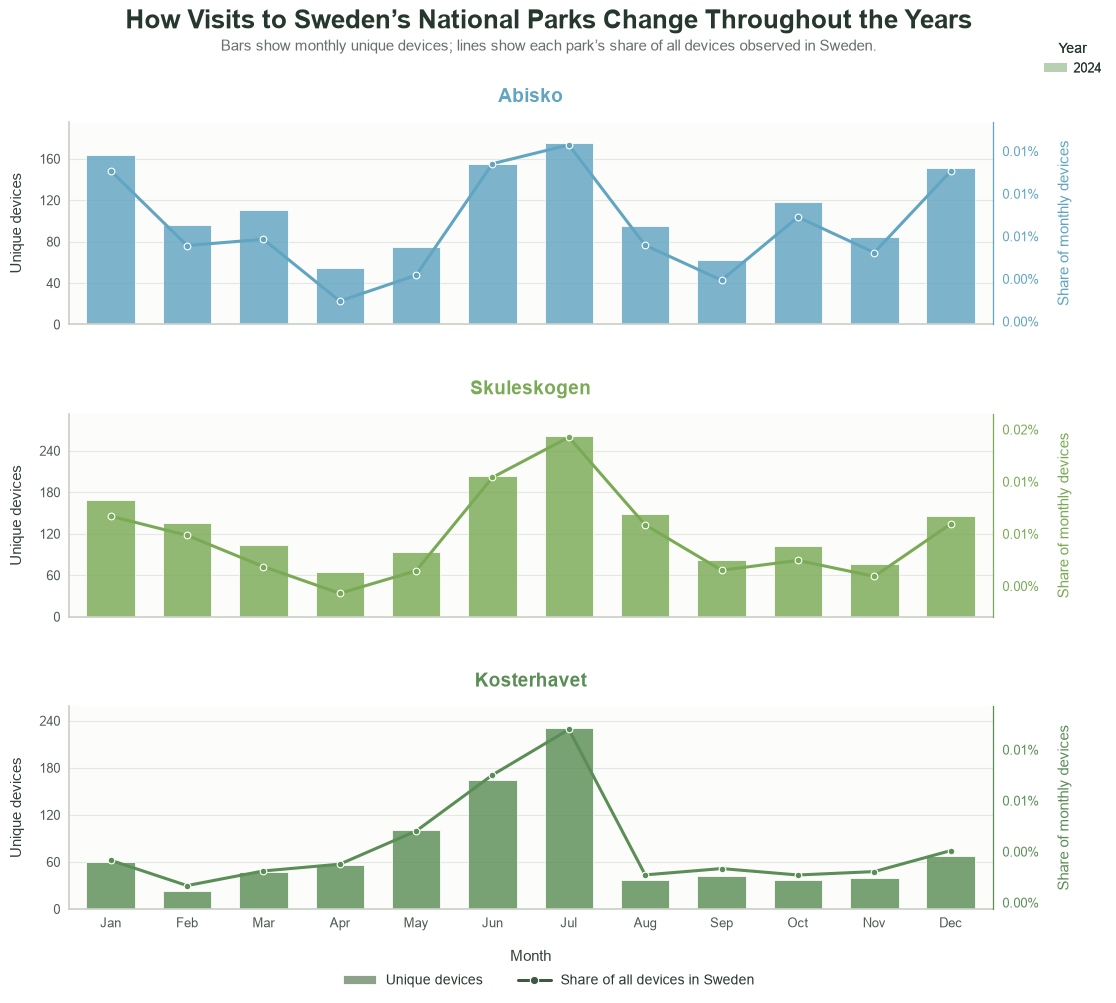

In [142]:
plot_combined_devices_by_month(
    data=normalized_devices,
    plot_title=(
        "How Visits to Sweden’s National Parks "
        "Change Throughout the Years"
    )
)